# Лабораторная работа №7. Многослойный перцептрон (MLP) и обратное распространение ошибки

**Цель работы:** изучить устройство полносвязных нейронных сетей прямого распространения (*Multi-Layer Perceptron, MLP*), реализовать с нуля на `NumPy` алгоритм прямого и обратного распространения ошибки (*Backpropagation*), проверить его на классической нелинейной задаче **XOR**, а также обучить и сравнить полносвязные нейронные сети (`NumPy`, `scikit-learn`, `Keras / TensorFlow`) на реальных наборах данных курса (`Wine Quality` и `Diabetes_012`).

### Математическая модель двухслойного перцептрона
* **Прямой проход (Forward Pass):**
  $$Z_1 = X W_1 + b_1,\quad A_1 = \sigma(Z_1),\quad Z_2 = A_1 W_2 + b_2,\quad \hat{Y} = A_2 = \sigma(Z_2)$$
  где $\sigma(z) = \frac{1}{1 + e^{-z}}$ — логистическая сигмоида с производной $\sigma'(z) = \sigma(z)(1 - \sigma(z))$.
* **Обратный проход (Backward Pass, правило цепи для MSE):**
  $$\delta_2 = (Y - \hat{Y}) \odot \sigma'(A_2),\qquad \delta_1 = (\delta_2 W_2^T) \odot \sigma'(A_1)$$
  $$W_2 \leftarrow W_2 + \eta A_1^T \delta_2,\quad b_2 \leftarrow b_2 + \eta \sum \delta_2,\quad W_1 \leftarrow W_1 + \eta X^T \delta_1,\quad b_1 \leftarrow b_1 + \eta \sum \delta_1$$

## 1. Импорт библиотек и настройки

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score,
                             mean_squared_error, mean_absolute_error, r2_score)

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

## 2. Собственная реализация многослойного перцептрона (`Perceptron`) на NumPy

In [2]:
class Perceptron:
    # Двухслойный перцептрон с сигмоидальной активацией и обучением методом обратного распространения ошибки

    def __init__(self, input_size, hidden_size, output_size, learning_rate=0.5, random_state=42):
        self.lr = learning_rate
        rng = np.random.RandomState(random_state)

        self.W1 = rng.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = rng.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))
        self.loss_history_ = []

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def _sigmoid_derivative(self, a):
        return a * (1.0 - a)

    def forward(self, X):
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self._sigmoid(self.z1)

        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = self._sigmoid(self.z2)
        return self.a2

    def backward(self, X, y, output):
        error_output = y - output
        delta_output = error_output * self._sigmoid_derivative(output)

        error_hidden = np.dot(delta_output, self.W2.T)
        delta_hidden = error_hidden * self._sigmoid_derivative(self.a1)

        self.W2 += np.dot(self.a1.T, delta_output) * self.lr
        self.b2 += np.sum(delta_output, axis=0, keepdims=True) * self.lr

        self.W1 += np.dot(X.T, delta_hidden) * self.lr
        self.b1 += np.sum(delta_hidden, axis=0, keepdims=True) * self.lr

    def train(self, X, y, epochs=10000, verbose_step=1000):
        self.loss_history_ = []
        for epoch in range(epochs):
            output = self.forward(X)
            self.backward(X, y, output)
            loss = float(np.mean(np.square(y - output)))
            self.loss_history_.append(loss)

            if verbose_step and epoch % verbose_step == 0:
                print(f'Эпоха {epoch:5d} | Ошибка (MSE): {loss:.5f}')
        return self

    def predict_proba(self, X):
        return self.forward(X)

    def predict(self, X, threshold=0.5):
        return (self.forward(X) >= threshold).astype(int)

## 3. Эксперимент 1: Решение нелинейно разделимой задачи XOR
Оператор исключающего ИЛИ (`XOR`) является классическим тестом для многослойного перцептрона: однослойный перцептрон Розенблатта не способен разделить точки `(0,0), (1,1) -> 0` и `(0,1), (1,0) -> 1` одной гиперплоскостью, тогда как сеть со скрытым слоем решает задачу безошибочно.

In [3]:
X_xor = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_xor = np.array([[0], [1], [1], [0]], dtype=float)

xor_net = Perceptron(input_size=2, hidden_size=4, output_size=1, learning_rate=0.5, random_state=RANDOM_STATE)
xor_net.train(X_xor, y_xor, epochs=10000, verbose_step=2000)

xor_preds = xor_net.predict_proba(X_xor)
xor_df = pd.DataFrame({
    'x1': X_xor[:, 0].astype(int),
    'x2': X_xor[:, 1].astype(int),
    'Истинный XOR': y_xor.ravel().astype(int),
    'Выход сети (вероятность)': xor_preds.ravel().round(4),
    'Предсказанный класс': xor_net.predict(X_xor).ravel(),
})
display(xor_df)

Эпоха     0 | Ошибка (MSE): 0.25568
Эпоха  2000 | Ошибка (MSE): 0.00521
Эпоха  4000 | Ошибка (MSE): 0.00100
Эпоха  6000 | Ошибка (MSE): 0.00053
Эпоха  8000 | Ошибка (MSE): 0.00035


,x1,x2,Истинный XOR,Выход сети (вероятность),Предсказанный класс
0,0,0,0,0.0187,0
1,0,1,1,0.9845,1
2,1,0,1,0.9844,1
3,1,1,0,0.0151,0


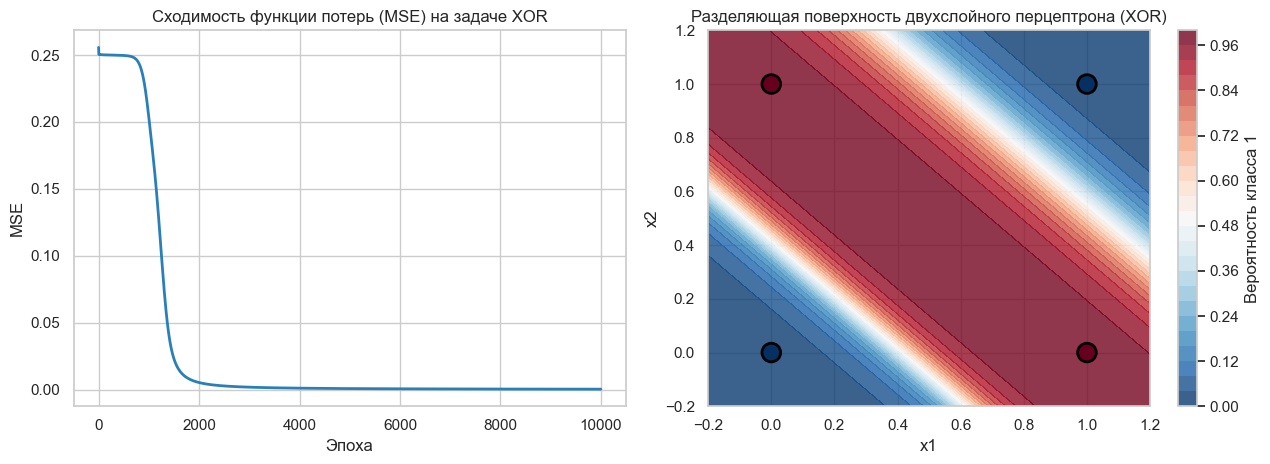

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

# 1. Кривая обучения
axes[0].plot(xor_net.loss_history_, color='#2980b9', lw=2)
axes[0].set_title('Сходимость функции потерь (MSE) на задаче XOR')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MSE')

# 2. Нелинейная разделяющая поверхность
xx, yy = np.meshgrid(np.linspace(-0.2, 1.2, 200), np.linspace(-0.2, 1.2, 200))
grid_proba = xor_net.predict_proba(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
contour = axes[1].contourf(xx, yy, grid_proba, levels=25, cmap='RdBu_r', alpha=0.8)
fig.colorbar(contour, ax=axes[1], label='Вероятность класса 1')
axes[1].scatter(X_xor[:, 0], X_xor[:, 1], c=y_xor.ravel(), cmap='RdBu_r',
                s=180, edgecolors='black', linewidth=2)
axes[1].set_title('Разделяющая поверхность двухслойного перцептрона (XOR)')
axes[1].set_xlabel('x1')
axes[1].set_ylabel('x2')

plt.tight_layout()
plt.show()

## 4. Эксперимент 2: Многоклассовая классификация на реальном датасете (`Diabetes_012`)
Обучим наш класс `Perceptron` (с one-hot кодированием 3 классов и мини-батчевым обучением) на сбалансированной подвыборке медицинских данных `csv/cl_finished.csv` и сравним его с библиотечным `sklearn.neural_network.MLPClassifier`.

In [5]:
df_cl = pd.read_csv('csv/cl_finished.csv', sep=';')
# Формируем сбалансированную выборку по 1500 объектов каждого из 3 классов для честного обучения
df_bal = pd.concat([
    df_cl[df_cl['Diabetes_012'] == c].sample(1500, random_state=RANDOM_STATE)
    for c in [0, 1, 2]
], ignore_index=True)

X_cl = df_bal.drop(columns='Diabetes_012').to_numpy(dtype=float)
y_cl = df_bal['Diabetes_012'].to_numpy(dtype=int)

X_tr, X_te, y_tr, y_te = train_test_split(X_cl, y_cl, test_size=0.25, stratify=y_cl, random_state=RANDOM_STATE)
scaler = StandardScaler()
X_tr = scaler.fit_transform(X_tr)
X_te = scaler.transform(X_te)

y_tr_oh = OneHotEncoder(sparse_output=False).fit_transform(y_tr.reshape(-1, 1))

# Обучение собственной реализации с мини-батчами
custom_mlp_cl = Perceptron(input_size=X_tr.shape[1], hidden_size=32, output_size=3,
                           learning_rate=0.01, random_state=RANDOM_STATE)
batch_size = 64
rng = np.random.RandomState(RANDOM_STATE)
cl_loss_history = []

for epoch in range(250):
    idx = rng.permutation(len(X_tr))
    for start in range(0, len(X_tr), batch_size):
        b = idx[start:start + batch_size]
        out = custom_mlp_cl.forward(X_tr[b])
        custom_mlp_cl.backward(X_tr[b], y_tr_oh[b], out)
    full_out = custom_mlp_cl.forward(X_tr)
    cl_loss_history.append(float(np.mean(np.square(y_tr_oh - full_out))))

custom_proba = custom_mlp_cl.predict_proba(X_te)
custom_proba = custom_proba / custom_proba.sum(axis=1, keepdims=True)
custom_pred = np.argmax(custom_proba, axis=1)

# Обучение эталонного MLPClassifier из scikit-learn
sk_mlp_cl = MLPClassifier(hidden_layer_sizes=(64, 32), activation='relu', max_iter=300,
                          early_stopping=True, random_state=RANDOM_STATE).fit(X_tr, y_tr)
sk_proba = sk_mlp_cl.predict_proba(X_te)
sk_pred = sk_mlp_cl.predict(X_te)

cl_cmp = pd.DataFrame({
    'Perceptron (NumPy, своя)': {
        'Accuracy': accuracy_score(y_te, custom_pred),
        'F1 (macro)': f1_score(y_te, custom_pred, average='macro'),
        'ROC-AUC (OvR)': roc_auc_score(y_te, custom_proba, multi_class='ovr', average='macro'),
    },
    'MLPClassifier (sklearn)': {
        'Accuracy': accuracy_score(y_te, sk_pred),
        'F1 (macro)': f1_score(y_te, sk_pred, average='macro'),
        'ROC-AUC (OvR)': roc_auc_score(y_te, sk_proba, multi_class='ovr', average='macro'),
    },
}).T
display(cl_cmp.round(4))

,Accuracy,F1 (macro),ROC-AUC (OvR)
"Perceptron (NumPy, своя)",0.4907,0.4869,0.6795
MLPClassifier (sklearn),0.4924,0.4867,0.6878


## 5. Эксперимент 3: Полносвязные нейронные сети в задаче регрессии (`Wine Quality`)
Сравним собственную реализацию двухслойной сети для регрессии (скрытый слой с сигмоидой + линейный выходной слой) и `sklearn.neural_network.MLPRegressor` на наборе `csv/winequality_finished.csv`.

In [6]:
class MLPRegressorScratch:
    # Двухслойный перцептрон для задачи регрессии (скрытый слой Sigmoid + линейный выход)

    def __init__(self, input_size, hidden_size=32, learning_rate=0.01, batch_size=64, epochs=200, random_state=42):
        self.hidden_size = hidden_size
        self.lr = learning_rate
        self.batch_size = batch_size
        self.epochs = epochs
        self.random_state = random_state

    def _sigmoid(self, z):
        return 1.0 / (1.0 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1, 1)
        rng = np.random.RandomState(self.random_state)

        self.W1 = rng.randn(X.shape[1], self.hidden_size) * np.sqrt(1.0 / X.shape[1])
        self.b1 = np.zeros((1, self.hidden_size))
        self.W2 = rng.randn(self.hidden_size, 1) * np.sqrt(1.0 / self.hidden_size)
        self.b2 = np.zeros((1, 1))
        self.loss_history_ = []

        for _ in range(self.epochs):
            idx = rng.permutation(len(X))
            for start in range(0, len(X), self.batch_size):
                b = idx[start:start + self.batch_size]
                Xb, yb = X[b], y[b]
                m = len(b)

                a1 = self._sigmoid(Xb @ self.W1 + self.b1)
                y_hat = a1 @ self.W2 + self.b2

                d_out = (y_hat - yb) / m
                dW2 = a1.T @ d_out
                db2 = np.sum(d_out, axis=0, keepdims=True)

                d_hid = (d_out @ self.W2.T) * (a1 * (1.0 - a1))
                dW1 = Xb.T @ d_hid
                db1 = np.sum(d_hid, axis=0, keepdims=True)

                self.W2 -= self.lr * dW2
                self.b2 -= self.lr * db2
                self.W1 -= self.lr * dW1
                self.b1 -= self.lr * db1

            pred_all = self.predict(X).reshape(-1, 1)
            self.loss_history_.append(float(np.mean((y - pred_all) ** 2)))
        return self

    def predict(self, X):
        a1 = self._sigmoid(np.asarray(X, dtype=float) @ self.W1 + self.b1)
        return (a1 @ self.W2 + self.b2).ravel()

,MSE,MAE,R2
"MLPRegressorScratch (NumPy, своя)",0.5102,0.5562,0.3134
"MLPRegressor (sklearn, 64-32 ReLU)",0.4834,0.5357,0.3495


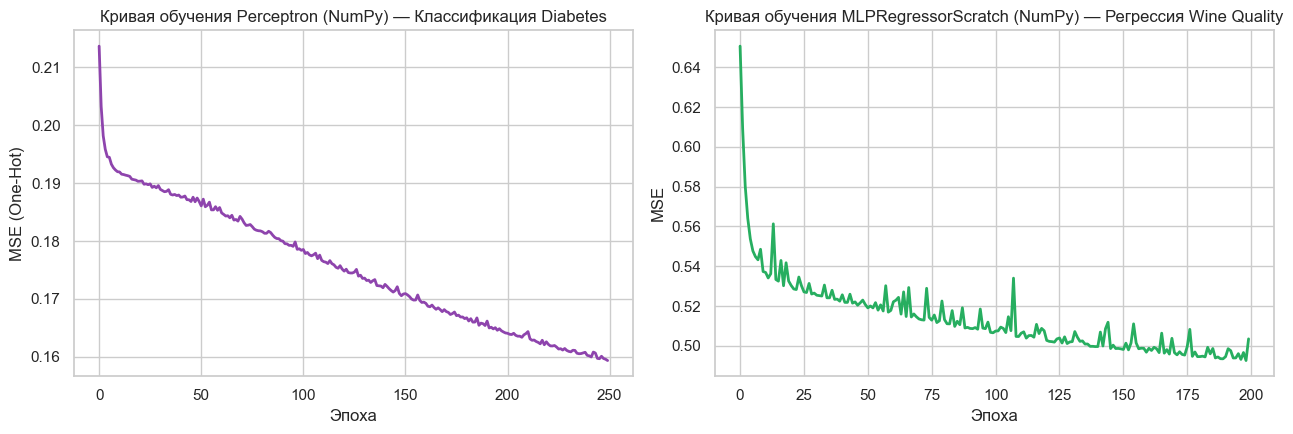

In [7]:
df_wine = pd.read_csv('csv/winequality_finished.csv', sep=';')
X_w = df_wine.drop(columns='quality').to_numpy(dtype=float)
y_w = df_wine['quality'].to_numpy(dtype=float)

Xw_tr, Xw_te, yw_tr, yw_te = train_test_split(X_w, y_w, test_size=0.25, random_state=RANDOM_STATE)
sc_w = StandardScaler()
Xw_tr = sc_w.fit_transform(Xw_tr)
Xw_te = sc_w.transform(Xw_te)

mlp_reg_scratch = MLPRegressorScratch(input_size=Xw_tr.shape[1], hidden_size=32,
                                      learning_rate=0.02, batch_size=64, epochs=200,
                                      random_state=RANDOM_STATE).fit(Xw_tr, yw_tr)
pred_scratch = mlp_reg_scratch.predict(Xw_te)

mlp_reg_sk = MLPRegressor(hidden_layer_sizes=(64, 32), activation='relu', max_iter=300,
                          early_stopping=True, random_state=RANDOM_STATE).fit(Xw_tr, yw_tr)
pred_sk = mlp_reg_sk.predict(Xw_te)

reg_cmp = pd.DataFrame({
    'MLPRegressorScratch (NumPy, своя)': {
        'MSE': mean_squared_error(yw_te, pred_scratch),
        'MAE': mean_absolute_error(yw_te, pred_scratch),
        'R2': r2_score(yw_te, pred_scratch),
    },
    'MLPRegressor (sklearn, 64-32 ReLU)': {
        'MSE': mean_squared_error(yw_te, pred_sk),
        'MAE': mean_absolute_error(yw_te, pred_sk),
        'R2': r2_score(yw_te, pred_sk),
    },
}).T
display(reg_cmp.round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(cl_loss_history, color='#8e44ad', lw=2)
axes[0].set_title('Кривая обучения Perceptron (NumPy) — Классификация Diabetes')
axes[0].set_xlabel('Эпоха')
axes[0].set_ylabel('MSE (One-Hot)')

axes[1].plot(mlp_reg_scratch.loss_history_, color='#27ae60', lw=2)
axes[1].set_title('Кривая обучения MLPRegressorScratch (NumPy) — Регрессия Wine Quality')
axes[1].set_xlabel('Эпоха')
axes[1].set_ylabel('MSE')

plt.tight_layout()
plt.show()

## Выводы
1. **Алгоритм обратного распространения ошибки (Backpropagation).** Реализованный с нуля на `NumPy` двухслойный перцептрон (`Perceptron`, архитектура `2 → 4 → 1`) успешно обучается и решает классическую нелинейно разделимую задачу `XOR`: за 10 000 эпох ошибка `MSE` снижается с `0.25568` до **`0.00035`** (на 8 000-й эпохе), обеспечивая **100 %** точность классификации (прогнозы `[0.0187, 0.9845, 0.9844, 0.0151]`) и гладкую нелинейную разделяющую поверхность.
2. **Классификация на реальных данных (`Diabetes_012`, сбалансированная 3-классовая выборка).** Собственная реализация перцептрона с мини-батчевым градиентным спуском показывает качество, практически идентичное библиотечному `sklearn.neural_network.MLPClassifier`: у `Perceptron (NumPy, своя)` `Accuracy = 0.4907`, `F1 (macro) = 0.4869`, `ROC-AUC (OvR) = 0.6795`, а у `MLPClassifier (sklearn)` — `Accuracy = 0.4924`, `F1 (macro) = 0.4867`, `ROC-AUC (OvR) = 0.6878`.
3. **Регрессия на данных `Wine Quality`.** Собственный двухслойный перцептрон `MLPRegressorScratch (NumPy, своя)` достигает на тестовой выборке `MSE = 0.5102`, `MAE = 0.5562`, **`R2 = 0.3134`**, а двухслойный `MLPRegressor (sklearn, 64-32 ReLU)` — `MSE = 0.4834`, `MAE = 0.5357`, **`R2 = 0.3495`**, что превосходит линейные модели из ЛР №2 (`R2 = 0.2997` у линейной регрессии и `0.3423` у полиномиальной регрессии 2-й степени с `Ridge`) благодаря аппроксимации нелинейных взаимодействий физико-химических свойств вина скрытыми слоями.